## Imports and loading

In [9]:
import pandas as pd
import numpy as np

from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from sklearn.impute import SimpleImputer
import html
import re

print("Caricamento dati...")


train_df = pd.read_csv("development.csv", na_values=['\\N', '0000-00-00 00:00:00', '  '], encoding='utf-8')
eval_df = pd.read_csv("evaluation.csv", na_values=['\\N', '0000-00-00 00:00:00', '  '])

print(train_df.isna().sum())



Caricamento dati...
Id               0
source         294
title            3
article       1878
page_rank        0
timestamp    27750
label            0
dtype: int64


## Text cleaning

In [10]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    
    # 1. Lowercase (sempre fondamentale per generalizzare)
    text = text.lower()
    
    # 2. Decodifica entità HTML (es. &amp; -> &)
    text = html.unescape(text)
    
    # 3. TRUCCO: Invece di rimuovere i tag con <[^>]+>, 
    # sostituiamo i caratteri sintattici dell'HTML e degli URL con spazi.
    # Così <a href="...  diventa " a href ... " e le parole restano!
    # Sostituiamo < > / . = " : _ - con spazi
    text = re.sub(r'[<>/\\\.=":_\-]', ' ', text)
    
    # 4. Rimuovi solo le parole puramente tecniche che non servono
    # es. 'http', 'www', 'href', 'com', 'jpg'
    # Puoi commentare questa parte se vuoi tenere tutto
    stop_garbage = r'\b(http|https|www|com|href|src|jpg|png|html|height|width|border)\b'
    
    # 3. GESTIONE NUMERI (La tua intuizione corretta)
    # Sostituisci i numeri con un token generico "NUM"
    # Esempio: "Oil rose by 5%" -> "Oil rose by NUM%"
    text = re.sub(r'\d+', 'NUM', text)
    
    # 6. Rimuovi singole lettere (refusi)
    text = re.sub(r'\b[a-z]\b', ' ', text)
    
    # 7. Normalizza spazi
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

train_df['title'] = train_df['title'].fillna('')
train_df['article'] = train_df['article'].fillna('')

eval_df['title'] = eval_df['title'].fillna('')
eval_df['article'] = eval_df['article'].fillna('')

train_df['title'] = train_df['title'].apply(clean_text)
eval_df['title'] = eval_df['title'].apply(clean_text)

train_df['article'] = train_df['article'].apply(clean_text)
eval_df['article'] = eval_df['article'].apply(clean_text)


train_df['text_content'] = train_df['title']+ ' ' + train_df['article']

eval_df['text_content'] = eval_df['title']+ ' ' + eval_df['article']

print("Dati caricati.")

Dati caricati.


In [11]:
print(f"Dataset originale: {len(train_df)} righe.")
train_df = train_df[train_df['text_content'] != " "]
print(f"Dataset dopo rimozione righe con title e article vuoti: {len(train_df)} righe.")


group_cols = ['text_content']

# 1. Funzione per determinare la moda o segnare il pareggio
# Se len(x.mode()) == 1, c'è una maggioranza chiara -> restituisce la moda.
# Altrimenti (len > 1), c'è un pareggio -> restituisce -1.
def get_majority_or_tie(x):
    modes = x.mode()
    if len(modes) == 1:
        return modes[0]
    else:
        return -1


# 2. Applica la logica
voted_labels = train_df.groupby(group_cols)['label'].transform(get_majority_or_tie)

# 3. Sovrascrivi la colonna label
train_df['label'] = voted_labels

# 4. Elimina PRIMA i pareggi (tutte le righe con -1 vengono scartate)
# Assicurati che -1 non sia una label valida nel tuo dataset originale!
train_df = train_df[train_df['label'] != -1]

# 5. Elimina i duplicati
# Ora rimangono solo gli articoli con una maggioranza chiara.
# Possiamo tenere la prima riga di ogni gruppo.
train_df = train_df.drop_duplicates(subset=group_cols, keep='first')

print(f"Dataset pulito: {len(train_df)} righe (pareggi eliminati).")




group_cols = ['article']

# 1. CREA UNA MASCHERA per separare i dati
# True per le righe da elaborare, False per quelle da ignorare (title vuoto)
mask_process = train_df['article'].str.strip() != ''

# 2. SEPARA IL DATAFRAME IN DUE PEZZI
df_to_process = train_df[mask_process].copy() # Righe con titolo valido
df_ignored = train_df[~mask_process].copy()   # Righe con title='' (da conservare intatte)

# 3. APPLICA LA LOGICA SOLO SU 'df_to_process'
if not df_to_process.empty:
    # Calcola la maggioranza
    voted_labels = df_to_process.groupby(group_cols)['label'].transform(get_majority_or_tie)
    
    # Assegna le nuove label
    df_to_process['label'] = voted_labels
    
    # Elimina i pareggi (-1)
    df_to_process = df_to_process[df_to_process['label'] != -1]
    
    # Elimina i duplicati (mantenendo una sola riga per titolo)
    df_to_process = df_to_process.drop_duplicates(subset=group_cols, keep='first')

# 4. RIUNISCI I DUE PEZZI
# Concateniamo le righe elaborate (pulite e deduplicate) con quelle ignorate (originali)
train_df = pd.concat([df_to_process, df_ignored], ignore_index=True)

print(f"Dataset finale dopo majority voting su 'article': {len(train_df)} righe.")



Dataset originale: 79997 righe.
Dataset dopo rimozione righe con title e article vuoti: 79996 righe.
Dataset pulito: 75496 righe (pareggi eliminati).
Dataset finale dopo majority voting su 'article': 74529 righe.


## Preprocessing

In [39]:
text_transformer = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 3),
    sublinear_tf=True,
    )


cat_transformer = OneHotEncoder(handle_unknown='ignore')

hour_transformer = Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ])
source_pipe = Pipeline([
    ('imputer',SimpleImputer(strategy='constant', fill_value='missing')),
    ('encoder', OneHotEncoder(max_categories=301, handle_unknown='ignore')),
])

preprocessor = ColumnTransformer(
    transformers=[
        ('txt', text_transformer, 'text_content'),
        ('ord', cat_transformer, ['page_rank']),
        ('hour', hour_transformer, ['hour_cos','hour_sin']),
        ('cat_source', source_pipe, ['source'])        
    ],
    remainder='passthrough'
)
train_df['day_of_week'] = pd.to_datetime(train_df['timestamp'], errors='coerce', format='%Y-%m-%d %H:%M:%S').dt.dayofweek
eval_df['day_of_week'] = pd.to_datetime(eval_df['timestamp'], errors='coerce', format='%Y-%m-%d %H:%M:%S').dt.dayofweek

train_df['is_weekend'] = train_df['day_of_week'].apply(lambda x: 1 if x >=5 else 0)
train_df['timestamp_missing'] = train_df['day_of_week'].apply(lambda x: 1 if pd.isna(x) else 0)
eval_df['is_weekend'] = eval_df['day_of_week'].apply(lambda x: 1 if x >=5 else 0)
eval_df['timestamp_missing'] = eval_df['day_of_week'].apply(lambda x: 1 if pd.isna(x) else 0)

train_df['text_length'] = train_df['text_content'].apply(lambda x: len(x))
eval_df['text_length'] = eval_df['text_content'].apply(lambda x: len(x))

train_df['hour_of_day'] = pd.to_datetime(train_df['timestamp'], errors='coerce', format='%Y-%m-%d %H:%M:%S').dt.hour
eval_df['hour_of_day'] = pd.to_datetime(eval_df['timestamp'], errors='coerce', format='%Y-%m-%d %H:%M:%S').dt.hour
train_df['hour_sin'] = np.sin(2 * np.pi * train_df['hour_of_day'] / 24)
train_df['hour_cos'] = np.cos(2 * np.pi * train_df['hour_of_day'] / 24)

eval_df['hour_sin'] = np.sin(2 * np.pi * eval_df['hour_of_day'] / 24)
eval_df['hour_cos'] = np.cos(2 * np.pi * eval_df['hour_of_day'] / 24)

X_eval = eval_df[['text_content', 'source','page_rank','is_weekend','timestamp_missing','hour_sin','hour_cos']]


X = train_df[['text_content', 'source','page_rank','is_weekend','timestamp_missing','hour_sin','hour_cos']]
y = train_df['label']


## Linear SVC

In [36]:
classifier = LinearSVC(random_state=42)
model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', classifier)
])


param_grid = {
    'clf__C': [0.1],
    'clf__class_weight': ['balanced'],
    'preprocessor__txt__ngram_range': [(1,3)],
    'preprocessor__txt__max_features': [300000],
    'preprocessor__txt__stop_words': ['english'],
    'preprocessor__txt__sublinear_tf': [True],
    'preprocessor__txt__lowercase': [True]
}

grid_search = GridSearchCV(
    model_pipeline, 
    param_grid, 
    cv=5, 
    scoring='f1_macro', 
    n_jobs=-1, 
    verbose=2
)

grid_search.fit(X, y)
print("LINEAR SVC - Grid Search Results:")
print(grid_search.best_params_)
print(f"Best Cross-Validation Macro F1: {grid_search.best_score_:.4f}")
best_model = grid_search.best_estimator_



Fitting 5 folds for each of 1 candidates, totalling 5 fits
[CV] END clf__C=0.1, clf__class_weight=balanced, preprocessor__txt__lowercase=True, preprocessor__txt__max_features=300000, preprocessor__txt__ngram_range=(1, 3), preprocessor__txt__stop_words=english, preprocessor__txt__sublinear_tf=True; total time=  31.0s
[CV] END clf__C=0.1, clf__class_weight=balanced, preprocessor__txt__lowercase=True, preprocessor__txt__max_features=300000, preprocessor__txt__ngram_range=(1, 3), preprocessor__txt__stop_words=english, preprocessor__txt__sublinear_tf=True; total time=  31.1s
[CV] END clf__C=0.1, clf__class_weight=balanced, preprocessor__txt__lowercase=True, preprocessor__txt__max_features=300000, preprocessor__txt__ngram_range=(1, 3), preprocessor__txt__stop_words=english, preprocessor__txt__sublinear_tf=True; total time=  31.7s
[CV] END clf__C=0.1, clf__class_weight=balanced, preprocessor__txt__lowercase=True, preprocessor__txt__max_features=300000, preprocessor__txt__ngram_range=(1, 3), p

In [27]:
best_model.fit(X, y)
y_eval_pred = best_model.predict(X_eval)

pd.DataFrame({
    'Id': eval_df['Id'],
    'Predicted': y_eval_pred}).to_csv('submission.csv', index=False)

# Logistic Regression

In [38]:
classifier=LogisticRegression(random_state=42,max_iter=1000)

model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', classifier)
])

param_grid = {
    'clf__C': [0.1],
    'clf__penalty': ['l2'],
    'clf__class_weight': ['balanced'],
    'preprocessor__txt__ngram_range': [(1,3)],
    'preprocessor__txt__max_features': [100000],
    'preprocessor__txt__max_df': [0.5],
    'preprocessor__txt__min_df': [3],
    'preprocessor__txt__stop_words': ['english'],
    'preprocessor__txt__sublinear_tf': [True],
    'preprocessor__txt__lowercase': [True]
}

grid_search = GridSearchCV(
    model_pipeline,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=2)

grid_search.fit(X, y)

print("LOGISTIC REGRESSION - Grid Search Results:")
print(grid_search.best_params_)
print(f"Best Cross-Validation Macro F1: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 1 candidates, totalling 5 fits


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarnin

[CV] END clf__C=0.1, clf__class_weight=balanced, clf__penalty=l2, preprocessor__txt__lowercase=True, preprocessor__txt__max_df=0.5, preprocessor__txt__max_features=100000, preprocessor__txt__min_df=3, preprocessor__txt__ngram_range=(1, 3), preprocessor__txt__stop_words=english, preprocessor__txt__sublinear_tf=True; total time= 1.1min
[CV] END clf__C=0.1, clf__class_weight=balanced, clf__penalty=l2, preprocessor__txt__lowercase=True, preprocessor__txt__max_df=0.5, preprocessor__txt__max_features=100000, preprocessor__txt__min_df=3, preprocessor__txt__ngram_range=(1, 3), preprocessor__txt__stop_words=english, preprocessor__txt__sublinear_tf=True; total time= 1.1min
[CV] END clf__C=0.1, clf__class_weight=balanced, clf__penalty=l2, preprocessor__txt__lowercase=True, preprocessor__txt__max_df=0.5, preprocessor__txt__max_features=100000, preprocessor__txt__min_df=3, preprocessor__txt__ngram_range=(1, 3), preprocessor__txt__stop_words=english, preprocessor__txt__sublinear_tf=True; total time=

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


LOGISTIC REGRESSION - Grid Search Results:
{'clf__C': 0.1, 'clf__class_weight': 'balanced', 'clf__penalty': 'l2', 'preprocessor__txt__lowercase': True, 'preprocessor__txt__max_df': 0.5, 'preprocessor__txt__max_features': 100000, 'preprocessor__txt__min_df': 3, 'preprocessor__txt__ngram_range': (1, 3), 'preprocessor__txt__stop_words': 'english', 'preprocessor__txt__sublinear_tf': True}
Best Cross-Validation Macro F1: 0.6845


In [29]:
best_model.fit(X, y)
y_eval_pred = best_model.predict(X_eval)

pd.DataFrame({
    'Id': eval_df['Id'],
    'Predicted': y_eval_pred}).to_csv('submission.csv', index=False)

# GRAFICO

Splitting dataset...
Starting sensitivity analysis on max_features...
Testing max_features=1000...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Testing max_features=5000...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Testing max_features=10000...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


... (6 outputs left out)

Testing max_features=200000...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Testing max_features=300000...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


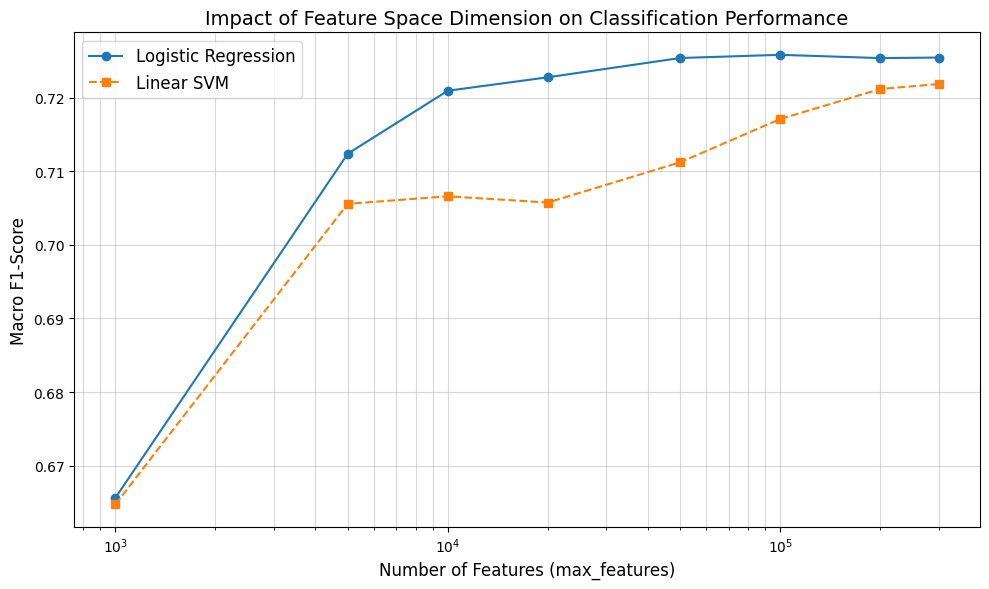

In [16]:
# 1. Definizione dello split 80/20 (Hold-out strategy per l'analisi del parametro)
# È FONDAMENTALE usare stratify=y per mantenere le proporzioni delle classi
print("Splitting dataset...")
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Definizione dei valori da testare
# Consiglio accademico: usate una scala logaritmica o geometrica per coprire ordini di grandezza diversi.
# Testiamo da 1.000 a 300.000 feature. Oltre 100-200k raramente c'è guadagno in F1-Macro.
max_features_list = [1000, 5000, 10000, 20000, 50000, 100000, 200000, 300000]

scores_lr = []
scores_svm = []

print("Starting sensitivity analysis on max_features...")

for max_feat in max_features_list:
    print(f"Testing max_features={max_feat}...")
    
    # Ricostruiamo il preprocessor con il parametro corrente
    # NOTA: Assicuratevi che il preprocessor sia definito correttamente prima
    # Qui assumo una struttura standard basata sul vostro snippet
    
    preprocessor.set_params(txt__max_features=max_feat)

    # Pipeline SVM
    pipe_svm = Pipeline([
        ('preprocessor', preprocessor),
        ('clf', LinearSVC(class_weight='balanced', random_state=42, dual=False))
    ])
    
    # Pipeline LogReg
    pipe_lr = Pipeline([
        ('preprocessor', preprocessor),
        ('clf', LogisticRegression(class_weight='balanced', random_state=42, n_jobs=-1, max_iter=1000))
    ])
    
    # Fit e Score su SVM
    pipe_svm.fit(X_train, y_train)
    y_pred_svm = pipe_svm.predict(X_val)
    scores_svm.append(f1_score(y_val, y_pred_svm, average='macro'))
    
    # Fit e Score su LogReg
    pipe_lr.fit(X_train, y_train)
    y_pred_lr = pipe_lr.predict(X_val)
    scores_lr.append(f1_score(y_val, y_pred_lr, average='macro'))

# 3. Plotting
plt.figure(figsize=(10, 6))
plt.plot(max_features_list, scores_lr, label='Logistic Regression', marker='o', linestyle='-')
plt.plot(max_features_list, scores_svm, label='Linear SVM', marker='s', linestyle='--')

plt.title('Impact of Feature Space Dimension on Classification Performance', fontsize=14)
plt.xlabel('Number of Features (max_features)', fontsize=12)
plt.ylabel('Macro F1-Score', fontsize=12)
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.legend(fontsize=12)
plt.xscale('log') # Fondamentale se spaziate molto i valori
plt.tight_layout()
plt.show()

In [30]:
# ... (codice precedente invariato)

# 4. Identificazione dei migliori parametri
# Usiamo np.argmax per trovare l'indice del valore massimo
best_idx_svm = np.argmax(scores_svm)
best_score_svm = scores_svm[best_idx_svm]
best_feat_svm = max_features_list[best_idx_svm]

best_idx_lr = np.argmax(scores_lr)
best_score_lr = scores_lr[best_idx_lr]
best_feat_lr = max_features_list[best_idx_lr]

print("\n--- SENSITIVITY ANALYSIS RESULTS ---")
print(f"SVM: Best Macro F1 = {best_score_svm:.4f} using max_features = {best_feat_svm}")
print(f"LR:  Best Macro F1 = {best_score_lr:.4f} using max_features = {best_feat_lr}")

# Suggerimento del Professore: 
# Se la differenza tra lo score a 50k e 300k è < 0.001, 
# nel report giustificate l'uso di 50k per il principio di parsimonia.


--- SENSITIVITY ANALYSIS RESULTS ---
SVM: Best Macro F1 = 0.7219 using max_features = 300000
LR:  Best Macro F1 = 0.7258 using max_features = 100000


In [41]:
preprocessor.set_params(
    txt__max_features=100000,
    txt__ngram_range=(1, 3),
    # Assicuriamoci che gli altri siano quelli standard usati nel loop
    txt__stop_words='english',
    txt__sublinear_tf=True
)

# 2. Configura il Modello "Campione" (Logistic Regression Default)
# Usiamo C=1.0 perché nel loop della sensitivity analysis non avevi cambiato C.
# max_iter=1000 serve per evitare i warning di convergenza.
final_model = LogisticRegression(
    class_weight='balanced', 
    random_state=42, 
    C=1.0,             # Default, quello che ti ha dato 0.7258
    solver='lbfgs',    # Default
    max_iter=1000      # Per sicurezza
)

# 3. Crea la Pipeline Finale
submission_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', final_model)
])

# 4. Addestramento su TUTTO il dataset di sviluppo (X, y)
# Non usare X_train, vogliamo sfruttare ogni singola riga di dati disponibile.
print("Addestramento del modello finale su tutto il dataset (100% dati)...")
submission_pipeline.fit(X, y)

# 5. Predizione sull'Evaluation Set (X_eval)
print("Predizione sull'Evaluation Set...")
y_eval_pred = submission_pipeline.predict(X_eval)

# 6. Creazione del file di sottomissione
print("Generazione file submission.csv...")
submission_df = pd.DataFrame({
    'Id': eval_df['Id'],
    'Predicted': y_eval_pred
})

submission_df.to_csv('submission.csv', index=False)
print("Fatto! File 'submission.csv' pronto per la leaderboard.")

Addestramento del modello finale su tutto il dataset (100% dati)...
Predizione sull'Evaluation Set...
Generazione file submission.csv...
Fatto! File 'submission.csv' pronto per la leaderboard.
